In [32]:
!pip install torch-levenberg-marquardt

In [80]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset
import torch_levenberg_marquardt as tlm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from bokeh.plotting import figure, show, output_notebook


In [81]:
df = pd.read_csv("/content/synthesize_enstatite.csv")

# shulman :

In [85]:


torch.set_float32_matmul_precision('high')

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

T_data = torch.tensor(df["T"].values, dtype=torch.float32).unsqueeze(1).to(device)
Cp_data = torch.tensor(df["Cp"].values, dtype=torch.float32).unsqueeze(1).to(device)

# Create dataset and dataloader
dataset = TensorDataset(T_data, Cp_data)
loader = tlm.utils.FastDataLoader(dataset, batch_size=512, repeat=10, shuffle=True, device=device)

# === Define Cp model as a neural net with 6 trainable params ===
class CpModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.tensor([7.73e-3], dtype=torch.float32))
        self.b = torch.nn.Parameter(torch.tensor([1.263e-3], dtype=torch.float32))
        self.c = torch.nn.Parameter(torch.tensor([3.0], dtype=torch.float32))
        self.d = torch.nn.Parameter(torch.tensor([8.47e-3], dtype=torch.float32))
        self.e = torch.nn.Parameter(torch.tensor([2.0825e-7], dtype=torch.float32))
        self.f = torch.nn.Parameter(torch.tensor([4.97e-2], dtype=torch.float32))

    def forward(self, T):
        T = torch.clamp(T, min=1e-6)
        term1 = self.a * T
        term2 = 1 - torch.exp(-self.b * T**2)
        term3 = 1.0
        term6 = torch.exp(-self.c * torch.sqrt(T))
        term4 = self.d * T**6
        term5 = self.e * T**4 * torch.exp(-self.f * T)
        return term1 * term2 * (term3 + term6 * term4 + term5)

# Instantiate models
model_adam = CpModel().to(device)
model_lm = CpModel().to(device)

print(f"Number of parameters: {sum(p.numel() for p in model_adam.parameters())}")

#  Wrap with training modules
module_adam = tlm.training.OptimizerModule(
    model=model_adam,
    optimizer=torch.optim.Adam(model_adam.parameters(), lr=1e-2),
    loss_fn=torch.nn.MSELoss(),
)

module_lm = tlm.training.LevenbergMarquardtModule(
    model=model_lm,
    loss_fn=tlm.loss.MSELoss(),
    learning_rate=1.0,
    solve_method="qr",
    attempts_per_step=10,
)

# === Train using Adam ===
print("\nTraining with Adam...")
start = time.perf_counter()
tlm.utils.fit(module_adam, loader, epochs=10)
end = time.perf_counter()
print(f"Adam training took {end - start:.2f} seconds")

# === Train using Levenberg-Marquardt ===
print("\nTraining with Levenberg-Marquardt...")
start = time.perf_counter()
tlm.utils.fit(module_lm, loader, epochs=10)
end = time.perf_counter()
print(f"LM training took {end - start:.2f} seconds")

# === Evaluate and Plot ===
print("\nPlotting results...")
with torch.no_grad():
    y_adam = model_adam(T_data)
    y_lm = model_lm(T_data)

T_np = T_data.cpu().numpy().flatten()
Cp_np = Cp_data.cpu().numpy().flatten()
y_adam_np = y_adam.cpu().numpy().flatten()
y_lm_np = y_lm.cpu().numpy().flatten()

output_notebook()
p = figure(title="Cp(T) Fit: Adam vs Levenberg-Marquardt", width=800, height=400)
p.circle(T_np, Cp_np, size=3, color="black", legend_label="Data")
p.line(T_np, y_adam_np, color="green", line_dash="dashed", line_width=2, legend_label="Adam")
p.line(T_np, y_lm_np, color="red", line_width=2, legend_label="LM")
p.legend.location = "top_left"
p.xaxis.axis_label = "T"
p.yaxis.axis_label = "Cp"
show(p)


Using device: cpu
Number of parameters: 6

Training with Adam...


Epoch 10/10: 100%|██████████| 10/10 [00:00<00:00, 190.86it/s, epoch_avg_loss=nan]


Training complete. Final epoch average loss: nan
Adam training took 0.55 seconds

Training with Levenberg-Marquardt...


Epoch 4/10: 100%|██████████| 10/10 [00:00<00:00, 102.41it/s, epoch_avg_loss=2.6668e-06]


Training complete. Final epoch average loss: 2.6668e-06
LM training took 0.34 seconds

Plotting results...


In [86]:
def print_parameters(model):
    print("\nBest-fit parameters:")
    for name, param in model.named_parameters():
        print(f"{name} = {param.item():.8f}")

print_parameters(model_lm)



Best-fit parameters:
a = 0.00221861
b = 0.00023855
c = 2.60478997
d = -0.00050550
e = 0.00000001
f = 0.01990949


In [87]:
a = 0.00221861
b = 0.00023855
c = 2.60478997
d = -0.00050550
e = 0.00000001
f = 0.01990949

# equation 1 :

Epoch 0: Loss = 6.025253
Epoch 200: Loss = 0.001988
Epoch 400: Loss = 0.001886
Epoch 600: Loss = 0.001866
Epoch 800: Loss = 0.001878
Epoch 1000: Loss = 0.001870
Epoch 1200: Loss = 0.002841
Epoch 1400: Loss = 0.001871
Epoch 1600: Loss = 0.001870
Epoch 1800: Loss = 0.001869


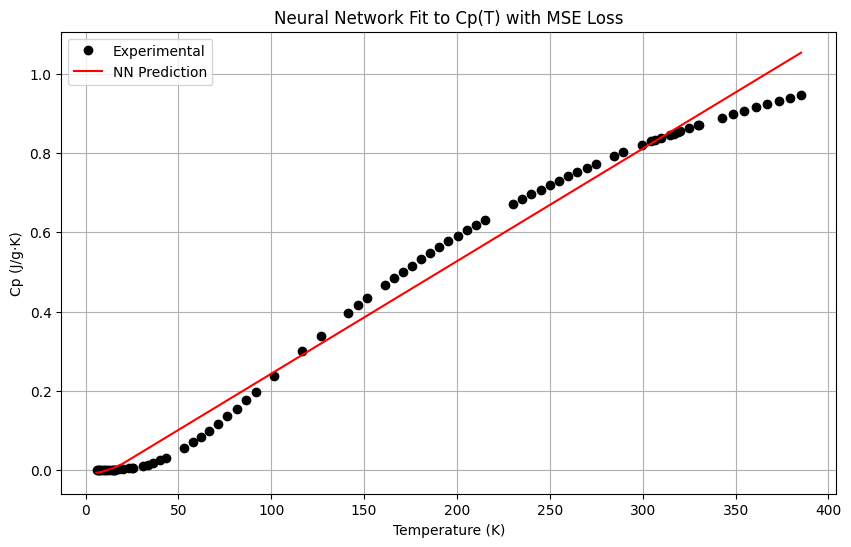

In [88]:

T = torch.tensor(df["T"].values, dtype=torch.float32).view(-1, 1)
Cp_exp = torch.tensor(df["Cp"].values, dtype=torch.float32).view(-1, 1)

# Define a simple MLP (Multi-Layer Perceptron)
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.net(x)

# Instantiate model, define loss and optimizer
model1 = SimpleNet()
criterion = nn.MSELoss()
optimizer = optim.Adam(model1.parameters(), lr=1e-3)

# Training loop
epochs = 2000
for epoch in range(epochs):
    model1.train()
    optimizer.zero_grad()
    outputs = model1(T)
    loss = criterion(outputs, Cp_exp)
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}")

# Plot predictions vs. data
model1.eval()
with torch.no_grad():
    predictions = model1(T).numpy()

plt.figure(figsize=(10, 6))
plt.plot(df["T"], df["Cp"], "ko", label="Experimental")
plt.plot(df["T"], predictions, "r-", label="NN Prediction")
plt.xlabel("Temperature (K)")
plt.ylabel("Cp (J/g·K)")
plt.title("Neural Network Fit to Cp(T) with MSE Loss")
plt.legend()
plt.grid(True)
plt.show()


# PINNS :

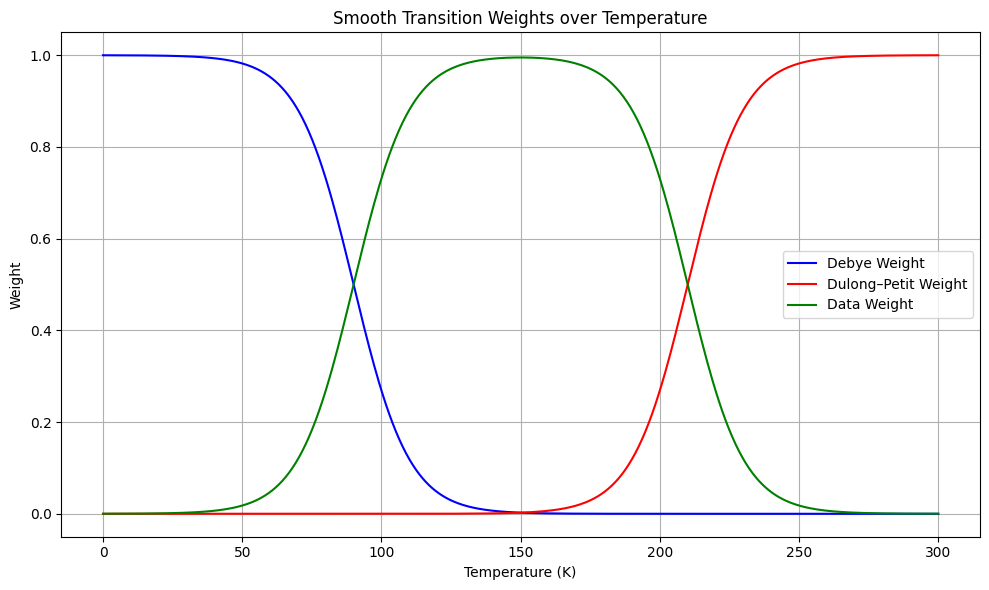

In [89]:

# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Parameters
T = np.linspace(0, 300, 500)
T_low = 80
T_high = 220
m = 10
s = 10

# Compute weights
w_debye = 1 - sigmoid((T - (T_low + m)) / s)
w_dp = sigmoid((T - (T_high - m)) / s)
w_data = 1 - w_debye - w_dp
w_data = np.clip(w_data, 0, 1)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(T, w_debye, label='Debye Weight', color='blue')
plt.plot(T, w_dp, label='Dulong–Petit Weight', color='red')
plt.plot(T, w_data, label='Data Weight', color='green')

plt.xlabel('Temperature (K)')
plt.ylabel('Weight')
plt.title('Smooth Transition Weights over Temperature')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Epoch 0, Loss: 0.188400
Epoch 500, Loss: 0.001739
Epoch 1000, Loss: 0.001481
Epoch 1500, Loss: 0.001011
Epoch 2000, Loss: 0.000847
Epoch 2500, Loss: 0.000726
Epoch 3000, Loss: 0.000707
Epoch 3500, Loss: 0.000702
Epoch 4000, Loss: 0.000698
Epoch 4500, Loss: 0.000692


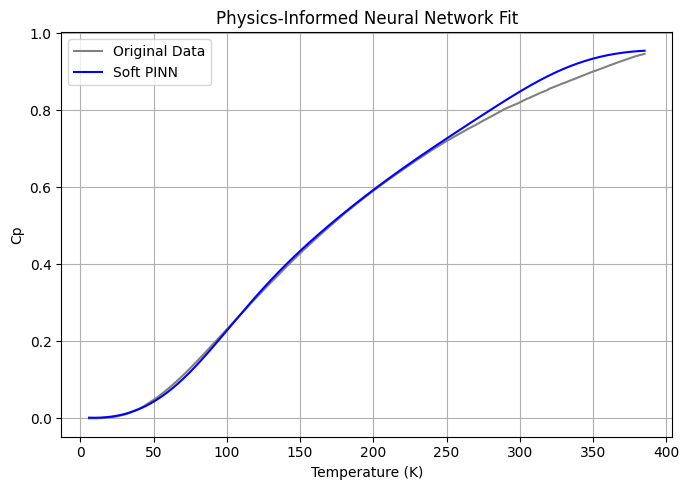

In [90]:


T_np = df.iloc[:, 0].values
Cp_np = df.iloc[:, 1].values

# Normalize T and Cp
T_min, T_max = T_np.min(), T_np.max()
Cp_min, Cp_max = Cp_np.min(), Cp_np.max()

def normalize(x, x_min, x_max):
    return (x - x_min) / (x_max - x_min)

def denormalize(x_norm, x_min, x_max):
    return x_norm * (x_max - x_min) + x_min

T_norm = normalize(T_np, T_min, T_max)
Cp_norm = normalize(Cp_np, Cp_min, Cp_max)

T_tensor = torch.tensor(T_norm, dtype=torch.float32).unsqueeze(1)
Cp_tensor = torch.tensor(Cp_norm, dtype=torch.float32).unsqueeze(1)


#  Neural Network

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.hidden(x)

model2 = Net()


#  Custom Physics Loss

def soft_mask(T, T_center, width):
    return torch.sigmoid((T - T_center) / width)

def physics_loss(T, Cp_pred, Cp_true, m=0.1, s=0.1):

    Cp_debye = T**3
    Cp_dp = torch.ones_like(T)

    # Losses
    loss_data = (Cp_pred - Cp_true)**2
    loss_debye = (Cp_pred - Cp_debye / Cp_debye.max())**2
    loss_dp = (Cp_pred - Cp_dp)**2

    # Weights
    T_low = normalize(10,T_min, T_max)
    T_high = normalize(350,T_min, T_max )
    w_debye = 1 - soft_mask(T, T_low + m, s)
    w_dp = soft_mask(T, T_high - m, s)
    w_data = 1.0 - w_debye - w_dp
    w_data = w_data.clamp(0.0, 1.0)

    # Final loss
    total_loss = w_data * loss_data + w_debye * loss_debye + w_dp * loss_dp
    return total_loss.mean()


#  Train the model

optimizer = torch.optim.Adam(model2.parameters(), lr=1e-3)
epochs = 5000
loss_history = []

for epoch in range(epochs):
    model2.train()
    optimizer.zero_grad()
    Cp_pred = model2(T_tensor)

    loss = physics_loss(T_tensor, Cp_pred, Cp_tensor, m=0.05, s=0.05)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")


#  Plot Results

model2.eval()
T_test = torch.linspace(0, 1, 300).unsqueeze(1)
Cp_test_pred = model2(T_test).detach().numpy()

# Denormalize
T_test_real = denormalize(T_test.numpy(), T_min, T_max)
Cp_test_real = denormalize(Cp_test_pred, Cp_min, Cp_max)

plt.figure(figsize=(7, 5))
plt.plot(T_np, Cp_np, label="Original Data", color="gray")
plt.plot(T_test_real, Cp_test_real, label="Soft PINN", color="blue")
plt.xlabel("Temperature (K)")
plt.ylabel("Cp")
plt.title("Physics-Informed Neural Network Fit")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


In [91]:
T_tensor_true = torch.tensor(normalize(T_np, T_min, T_max), dtype=torch.float32).unsqueeze(1)

model2.eval()
with torch.no_grad():
    Cp_pred_norm = model2(T_tensor_true).squeeze().numpy()

y_pred3 = denormalize(Cp_pred_norm, Cp_min, Cp_max)


# comparaison :

In [92]:
def Cp_shulman(T , a=7.73e-3 , b=1.263e-3 ,c=3 ,d=8.47e-3 , e=2.0825e-7 ,f=4.97e-2 ):
    T = np.clip(T, 1e-6, None)
    term1 = a * T
    term2 = 1 - np.exp(-b * T**2)
    term3 = 1
    term6 = np.exp(-c * np.sqrt(T))
    term4 = d * (T**6)
    term5 = e * T**4 * np.exp(- f* T)
    return term1 * term2 * (term3 + term6 * term4 + term5)



               Model       MSE       MAE        R²
0           Shullman  0.000127  0.008666  0.998998
1  Fitting with PySR  0.001869  0.035441  0.985275
2  Soft PINNs + PySR  0.000253  0.010578  0.998010


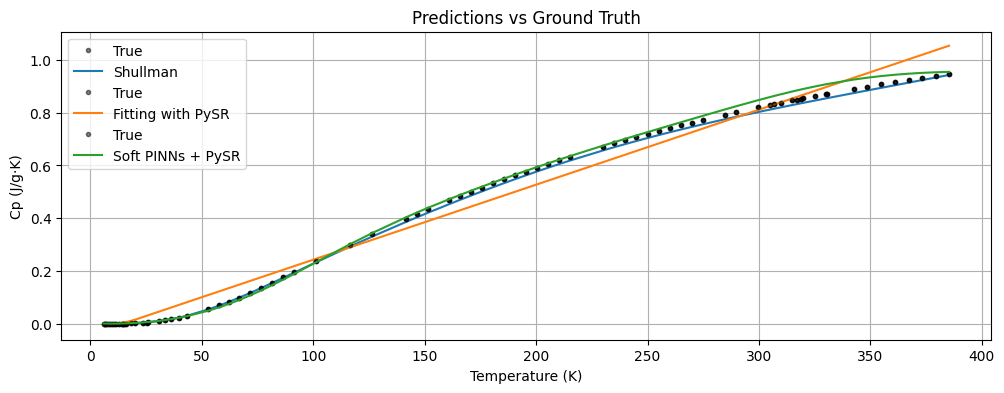

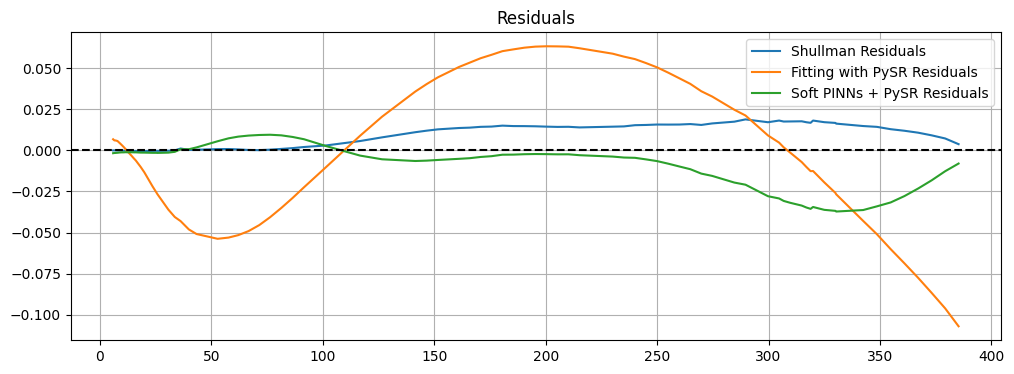

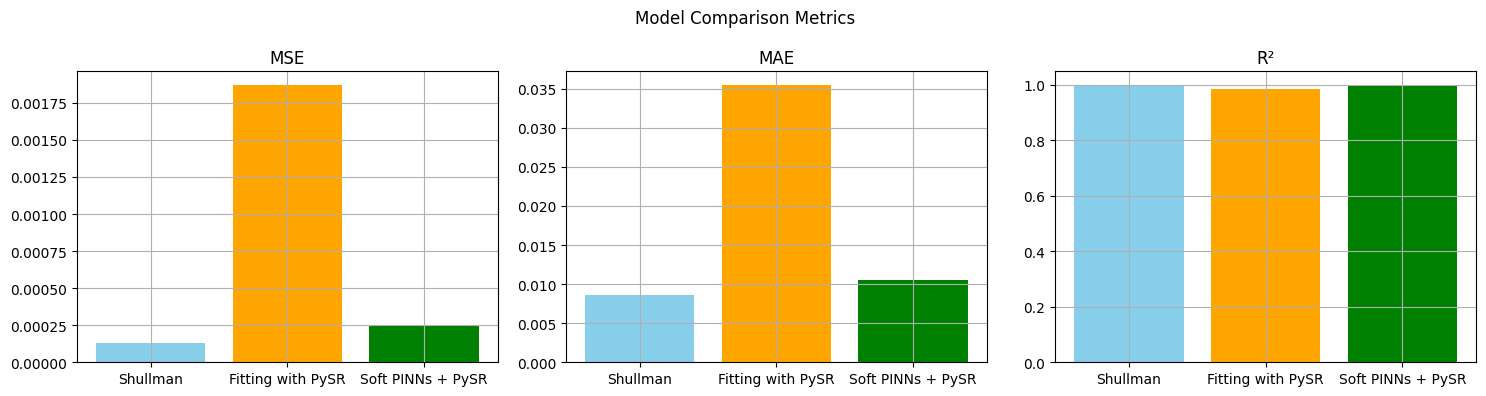

In [93]:


T = df["T"].values
Cp_exp = df["Cp"].values
T_tensor = torch.tensor(T, dtype=torch.float32).view(-1, 1)

# Predictions
y_pred1 = Cp_shulman(T, a, b, c, d, e, f)
y_pred2 = model1(T_tensor).detach().numpy().flatten()

# Model comparison
model_names = ['Shullman', 'Fitting with PySR', 'Soft PINNs + PySR']
predictions = [y_pred1, y_pred2, y_pred3]

# Metrics
results = []
for name, pred in zip(model_names, predictions):
    mse = mean_squared_error(Cp_exp, pred)
    mae = mean_absolute_error(Cp_exp, pred)
    r2 = r2_score(Cp_exp, pred)
    results.append({'Model': name, 'MSE': mse, 'MAE': mae, 'R²': r2})

df_metrics = pd.DataFrame(results)
print(df_metrics)

# --- Plot Predictions ---
plt.figure(figsize=(12, 4))
for name, pred in zip(model_names, predictions):
    plt.plot(T, Cp_exp, "k.", label="True", alpha=0.5)
    plt.plot(T, pred, label=name)
plt.xlabel("Temperature (K)")
plt.ylabel("Cp (J/g·K)")
plt.title("Predictions vs Ground Truth")
plt.legend()
plt.grid()
plt.show()

# --- Residuals ---
plt.figure(figsize=(12, 4))
for name, pred in zip(model_names, predictions):
    residuals = Cp_exp - pred
    plt.plot(T, residuals, label=f"{name} Residuals")
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals")
plt.legend()
plt.grid()
plt.show()

# --- Metrics Bar Chart ---
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, metric in enumerate(['MSE', 'MAE', 'R²']):
    ax[i].bar(model_names, df_metrics[metric], color=['skyblue', 'orange', 'green'])
    ax[i].set_title(metric)
    ax[i].grid(True)

plt.suptitle("Model Comparison Metrics")
plt.tight_layout()
plt.show()
